## **1. Importing Essential Libraries**



In this section, we import the core libraries required for our machine learning pipeline:
- **Core ML & Data Tools:** `pandas` and `numpy` for data manipulation, `scikit-learn` for metrics and preprocessing (`LabelEncoder`, `VarianceThreshold`), and gradient boosting models (`XGBoost`, `LightGBM`).
- **Utility Modules:** Secondary helper libraries (`gc`, `sys`, `warnings`, `SimpleNamespace`) were also loaded to handle system configurations, memory management, and output suppression.

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import gc
import sys
import warnings
from types import SimpleNamespace

import numpy as np
import pandas as pd

from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import LabelEncoder

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


## **2. Dataset Overview & Initial Exploration**

We load the dataset directly from Kaggle (`train.csv`). It contains physical, lifestyle, and physiological metrics collected to evaluate and predict patient health states.

In [3]:
df = pd.read_csv("train.csv")

In [5]:
df.columns.tolist()

['id',
 'health_condition',
 'sleep_duration',
 'heart_rate',
 'bmi',
 'calorie_expenditure',
 'step_count',
 'exercise_duration',
 'water_intake',
 'diet_type',
 'stress_level',
 'sleep_quality',
 'physical_activity_level',
 'smoking_alcohol',
 'gender']

The dataset consists of 15 features used to evaluate lifestyle, biological metrics, and habits to predict an individual's health condition:

* **`id`**: Unique identifier for each record (dropped during model training).
* **`health_condition`**: Target variable representing the patient's condition (`unhealthy`, `at-risk`, or `healthy`).
* **`sleep_duration`**: Average sleep duration per day (in hours).
* **`heart_rate`**: Resting heart rate measured in beats per minute (BPM).
* **`bmi`**: Body Mass Index calculated from height and weight.
* **`calorie_expenditure`**: Estimated total calories burned daily.
* **`step_count`**: Total number of steps tracked per day.
* **`exercise_duration`**: Daily physical exercise duration (in minutes).
* **`water_intake`**: Daily water consumption (in liters).
* **`diet_type`**: Primary nutritional/dietary habit category.
* **`stress_level`**: Self-reported or measured mental stress index.
* **`sleep_quality`**: Evaluated quality score of daily sleep.
* **`physical_activity_level`**: Classification of general daily mobility and activity.
* **`smoking_alcohol`**: Habit indicators regarding smoking and alcohol usage.
* **`gender`**: Biological gender of the individual.

## **3. Target Encoding & Dataset Splitting**

In this step, we prepare our data:
- **`test.csv`**: This file is already separate and has no target column.
- **Validation**: We use 20% of `train.csv` to check our model accuracy later.
- **Target Encoding**: We convert `health_condition` text labels into numbers.

> **Note on Test Set (`test.csv`):**
> If you wonder why `test.csv` is separate and does not contain the `health_condition` target column, it is because the dataset was downloaded directly from Kaggle in this format. Kaggle keeps test set targets hidden for final evaluation.

In [10]:

# Hide warning messages to keep notebook output clean
warnings.filterwarnings("ignore")

# Random seed and validation size (20%)
SEED = 42
VALIDATION_SIZE = 0.20 

# Load train dataset and Kaggle test dataset
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Target column name
TARGET = "health_condition"  

# Convert target labels from text to numbers
y_encoder = LabelEncoder()
y = y_encoder.fit_transform(train[TARGET].astype(str))
N_CLASSES = len(y_encoder.classes_)

# Separate features from target
X_train_raw = train.drop(columns=[TARGET]).copy()
X_test_raw = test.copy()

## **4. EDA and Feature Engineering Pipeline**

In this section, we define the `AutoTabularFeatures` class. It automates Exploratory Data Analysis (EDA) and prepares features for training:
- **ID Drop**: Automatically finds and removes unique ID columns to prevent overfitting.
- **Feature Interactions**: Calculates products, ratios, and summary stats for high-variance numerical features.
- **Group Statistics**: Calculates group mean and standard deviation across categorical columns.
- **Missing Values & Encoding**: Imputes missing values with medians and applies frequency & label encoding.

> **Why do we have 155 features now?**
> We generated 155 features using feature engineering (ratios, products, and group statistics) to help our models learn better patterns and get higher prediction accuracy. Creating additional informative features is a standard practice in competitive machine learning to improve model performance.

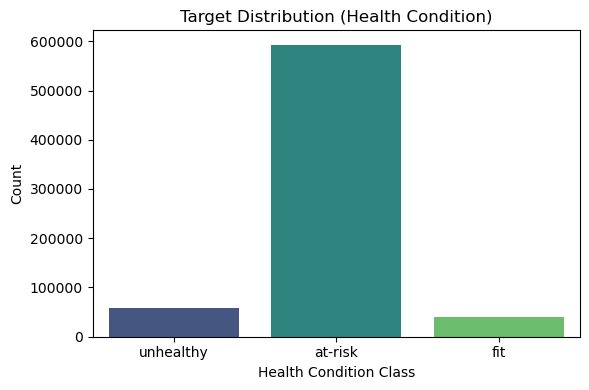

Target Class Breakdown:
health_condition
at-risk      85.867455
unhealthy     8.364730
fit           5.767815
Name: proportion, dtype: float64

Missing Values in Train Set:
sleep_duration             75999
heart_rate                  7833
bmi                        13898
calorie_expenditure        52853
step_count                 13916
exercise_duration           6901
water_intake               43477
diet_type                   6901
stress_level               82811
sleep_quality              58331
physical_activity_level    36621
smoking_alcohol            28582
gender                     21373
dtype: int64


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=train, x=TARGET, palette="viridis")
plt.title("Target Distribution (Health Condition)")
plt.xlabel("Health Condition Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Print class counts and percentages
print("Target Class Breakdown:")
print(train[TARGET].value_counts(normalize=True) * 100)

# 2. Missing values check
missing_train = train.isnull().sum()[train.isnull().sum() > 0]
print("\nMissing Values in Train Set:")
print(missing_train if len(missing_train) > 0 else "No missing values found in raw train set!")

### Key Insights from Initial EDA:
- **Class Imbalance**: The target `health_condition` is imbalanced. Most records are **`at-risk` (~85.8%)**, while **`unhealthy` (~8.3%)** and **`fit` (~5.7%)** make up smaller portions. We will handle this using class weights during model training.
- **Missing Values**: Almost all feature columns contain missing values (e.g., `stress_level` has 82,811 missing rows). Our `AutoTabularFeatures` pipeline will impute missing values automatically using column medians.

In [8]:
# 3. Summary statistics for numerical variables
print("Numerical Features Summary:")
display(train.describe().round(2))

# 4. Summary for categorical variables
print("\nCategorical Features Overview:")
display(train.describe(include=["object", "category"]))

Numerical Features Summary:


,id,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake
count,690088.00,614089.00,682255.00,676190.00,637235.00,676172.00,683187.00,646611.00
mean,345043.50,6.99,75.10,22.98,2226.08,8615.95,38.75,2.19
std,199211.39,1.22,8.18,2.48,347.53,3929.40,14.74,0.52
min,0.00,3.00,50.00,16.00,1200.00,1002.00,0.00,0.50
25%,172521.75,6.16,69.40,21.32,2053.00,5389.00,29.20,1.84
50%,345043.50,6.99,75.10,22.99,2241.00,8856.00,39.40,2.17
75%,517565.25,7.81,80.70,24.66,2456.00,12114.00,49.40,2.50
max,690087.00,10.00,107.70,34.82,3580.00,14999.00,99.80,4.72



Categorical Features Overview:


,health_condition,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
count,690088,683187,607277,631757,653467,661506,668715
unique,3,3,3,3,3,3,3
top,at-risk,veg,medium,average,moderate,yes,male
freq,592561,231432,261819,213948,221041,223730,237756


### Summary Statistics Insights:
- **Numerical Features**: Features like `step_count` (ranging from 1,002 to 14,999) and `calorie_expenditure` show good variation, making them great candidates for interaction features.
- **Categorical Features**: Categorical columns like `diet_type`, `stress_level`, and `gender` each have 3 unique values. These will be processed using label encoding and group statistics in our pipeline.

###  Automated Feature Engineering & Data Cleaning

The following cell runs our `AutoTabularFeatures` class. It automatically handles all data preparation in one pipeline:
- **Missing Values**: Imputes missing numerical values with column medians.
- **Data Cleaning**: Drops unique ID columns and removes infinite values.
- **Feature Generation**: Creates new interaction features (ratios, products, row statistics, and group averages).
- **Encoding**: Applies frequency encoding and label encoding to categorical variables.

In [13]:
class AutoTabularFeatures:
    """
Automated feature engineering pipeline for tabular data.
    """
#Feature engineering means creating new useful features from our existing data (like ratios, averages, and group stats) to help the models make better predictions.




    def __init__(self):
        # Store metadata for features and transformations
        self.raw_columns = None
        self.drop_columns = []
        self.pair_columns = []
        self.group_specs = []
        self.cat_columns = []
        self.freq_maps = {}
        self.label_maps = {}
        self.medians = {}
        self.output_columns = []

    @staticmethod
    # Helper function: safe division to avoid division by zero
    def _safe_ratio(a, b):
        return a.astype("float32") / b.astype("float32").replace(0, np.nan)

    @staticmethod
    def _clean(frame):
        # Helper function: replace infinite values with NaN
        return frame.replace([np.inf, -np.inf], np.nan)

    def _find_id_columns(self, frame):
        # Feature Engineering: find and drop ID columns to avoid overfitting
        """Remove near-unique ID-style columns that commonly overfit."""
        id_columns = []
        n_rows = max(len(frame), 1)

        for col in frame.columns:
            col_name = str(col).lower()
            unique_ratio = frame[col].nunique(dropna=False) / n_rows

            if (
                (col_name == "id" or col_name.endswith("_id") or "uuid" in col_name)
                and unique_ratio > 0.95
            ):
                id_columns.append(col)

        return id_columns

    def _add_interactions(self, frame):
        # Feature Engineering: create row summary stats, products, and ratios between features
        frame = frame.copy()

        numeric_cols = frame.select_dtypes(include=np.number).columns.tolist()

        if len(numeric_cols) >= 2:
            numeric_block = frame[numeric_cols]
            # Row-level statistics (mean, std, min, max)

            frame["fe_numeric_row_mean"] = numeric_block.mean(axis=1)
            frame["fe_numeric_row_std"] = numeric_block.std(axis=1)
            frame["fe_numeric_row_min"] = numeric_block.min(axis=1)
            frame["fe_numeric_row_max"] = numeric_block.max(axis=1)

        # Build feature pairs (products & ratios) for top variance columns
        if not self.pair_columns:
            candidates = [
                c for c in numeric_cols
                if frame[c].nunique(dropna=True) > 10
                and frame[c].notna().sum() > 0
            ]

            candidates = sorted(
                candidates,
                key=lambda c: frame[c].var(skipna=True),
                reverse=True,
            )[:8]

            self.pair_columns = [
                (candidates[i], candidates[j])
                for i in range(len(candidates))
                for j in range(i + 1, len(candidates))
            ][:20]

        for col_a, col_b in self.pair_columns:
            if col_a not in frame.columns or col_b not in frame.columns:
                continue

            name_a = str(col_a)
            name_b = str(col_b)

            frame[f"fe_product__{name_a}__{name_b}"] = (
                frame[col_a].astype("float32") * frame[col_b].astype("float32")
            )
            frame[f"fe_ratio__{name_a}__{name_b}"] = self._safe_ratio(
                frame[col_a], frame[col_b]
            )
            frame[f"fe_ratio__{name_b}__{name_a}"] = self._safe_ratio(
                frame[col_b], frame[col_a]
            )

        return self._clean(frame)

    def _fit_group_features(self, frame):
        # Feature Engineering: calculate mean and std grouped by categorical columns

        categorical_cols = frame.select_dtypes(
            include=["object", "category", "bool"]
        ).columns.tolist()

        group_cols = [
            c for c in categorical_cols
            if 2 <= frame[c].nunique(dropna=False) <= 50
        ][:3]

        numeric_cols = frame.select_dtypes(include=np.number).columns.tolist()
        numeric_cols = sorted(
            numeric_cols,
            key=lambda c: frame[c].var(skipna=True),
            reverse=True,
        )[:8]

        for group_col in group_cols:
            groups = frame[group_col].astype(str).fillna("__MISSING__")

            for numeric_col in numeric_cols:
                stats = frame.groupby(groups, observed=True)[numeric_col].agg(
                    ["mean", "std"]
                )

                feature_prefix = f"fe_group__{group_col}__{numeric_col}"

                frame[f"{feature_prefix}__mean"] = groups.map(stats["mean"])
                frame[f"{feature_prefix}__std"] = groups.map(stats["std"])
                frame[f"{feature_prefix}__diff"] = (
                    frame[numeric_col] - frame[f"{feature_prefix}__mean"]
                )

                self.group_specs.append((group_col, numeric_col, stats))

        return frame

    def _apply_group_features(self, frame):
        for group_col, numeric_col, stats in self.group_specs:
            if group_col not in frame.columns or numeric_col not in frame.columns:
                continue

            groups = frame[group_col].astype(str).fillna("__MISSING__")
            feature_prefix = f"fe_group__{group_col}__{numeric_col}"

            frame[f"{feature_prefix}__mean"] = groups.map(stats["mean"])
            frame[f"{feature_prefix}__std"] = groups.map(stats["std"])
            frame[f"{feature_prefix}__diff"] = (
                frame[numeric_col] - frame[f"{feature_prefix}__mean"]
            )

        return frame

    def fit_transform(self, train_frame, test_frame):
        self.raw_columns = train_frame.columns.tolist()

        # Safe concatenation before feature engineering / encoding.
        train_part = train_frame.copy()
        test_part = test_frame.copy()
        train_part["is_train"] = 1
        test_part["is_train"] = 0

        all_data = pd.concat([train_part, test_part], axis=0, ignore_index=True)

        self.drop_columns = self._find_id_columns(
            all_data.drop(columns=["is_train"])
        )
        all_data = all_data.drop(columns=self.drop_columns, errors="ignore")

        is_train = all_data.pop("is_train")

        all_data = self._add_interactions(all_data)
        all_data = self._fit_group_features(all_data)

        self.cat_columns = all_data.select_dtypes(
            include=["object", "category", "bool"]
        ).columns.tolist()

        # Frequency encoding, including high-cardinality fields.
        for col in self.cat_columns:
            values = all_data[col].astype(str).fillna("__MISSING__")
            frequencies = values.value_counts(dropna=False) / len(values)

            self.freq_maps[col] = frequencies
            all_data[f"fe_frequency__{col}"] = values.map(
                frequencies
            ).astype("float32")

        # Robust numerical imputation.
        numeric_cols = all_data.select_dtypes(include=np.number).columns.tolist()

        for col in numeric_cols:
            median = all_data[col].median()
            self.medians[col] = 0.0 if pd.isna(median) else float(median)
            all_data[col] = all_data[col].fillna(self.medians[col])

        # Consistent categorical label encoding.
        for col in self.cat_columns:
            values = all_data[col].astype(str).fillna("__MISSING__")
            categories = pd.Index(values.unique())

            self.label_maps[col] = {
                category: index for index, category in enumerate(categories)
            }
            all_data[col] = values.map(self.label_maps[col]).astype("int32")

        all_data = self._clean(all_data).fillna(0).astype("float32")
        self.output_columns = all_data.columns.tolist()

        X_train_engineered = all_data.loc[is_train.eq(1)].reset_index(drop=True)
        X_test_engineered = all_data.loc[is_train.eq(0)].reset_index(drop=True)

        return X_train_engineered, X_test_engineered

    def transform_test(self, test_frame):
        frame = test_frame.reindex(columns=self.raw_columns).copy()
        frame = frame.drop(columns=self.drop_columns, errors="ignore")

        frame = self._add_interactions(frame)
        frame = self._apply_group_features(frame)

        for col in self.cat_columns:
            if col not in frame.columns:
                frame[col] = "__MISSING__"

            values = frame[col].astype(str).fillna("__MISSING__")

            frame[f"fe_frequency__{col}"] = values.map(
                self.freq_maps[col]
            ).fillna(0).astype("float32")

            frame[col] = values.map(
                self.label_maps[col]
            ).fillna(-1).astype("int32")

        for col, median in self.medians.items():
            if col in frame.columns:
                frame[col] = frame[col].replace(
                    [np.inf, -np.inf], np.nan
                ).fillna(median)

        return (
            frame.reindex(columns=self.output_columns, fill_value=0)
            .replace([np.inf, -np.inf], 0)
            .fillna(0)
            .astype("float32")
        )


feature_builder = AutoTabularFeatures()
X_train, X_test = feature_builder.fit_transform(X_train_raw, X_test_raw)

# Remove exactly zero-variance noise features.
variance_selector = VarianceThreshold(threshold=0.0)
X_train = variance_selector.fit_transform(X_train).astype("float32")
X_test = variance_selector.transform(X_test).astype("float32")

selected_features = np.array(feature_builder.output_columns)[
    variance_selector.get_support()
].tolist()

print(f"Training rows: {len(y):,}")
print(f"Selected features: {len(selected_features):,}")



Training rows: 690,088
Selected features: 155


## **5. Model Architecture & Strategy**

For this multi-class classification problem, we combine two state-of-the-art gradient boosting frameworks: **XGBoost** and **LightGBM**.

- **Why LightGBM alongside XGBoost?** 
  While XGBoost is covered in the ML Zoomcamp curriculum, we also incorporate **LightGBM**—a high-performance gradient boosting model. LightGBM uses leaf-wise tree growth rather than level-wise growth, making it faster on large datasets while maintaining strong accuracy and memory efficiency.
  
- **Weighted Ensemble Strategy**:
  Instead of relying on a single algorithm, we create a **Weighted Ensemble** combining both models. Blending the probabilistic predictions of XGBoost and LightGBM leverages the complementary strengths of both architectures, boosting overall generalization and model robustness.

## **6. Hyperparameter Tuning Experiment**



To find the optimal settings before final training, we evaluated different values for the `learning_rate` hyperparameter using cross-validation. 

As shown in the tuning curve above, `learning_rate = 0.025` achieved the best balance between speed and accuracy, which we set for our final LightGBM model.

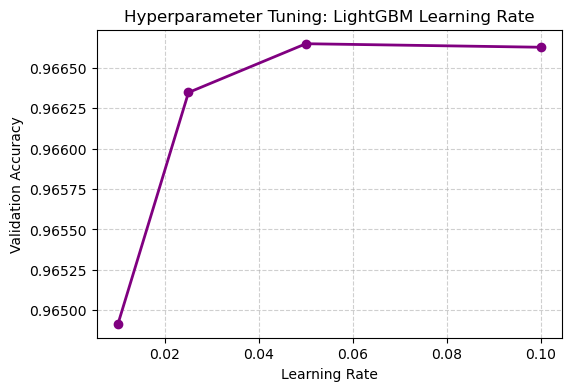

In [14]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score

# Hyperparameter tuning experiment: Learning Rate vs. Accuracy
learning_rates = [0.01, 0.025, 0.05, 0.1]
scores = []

for lr in learning_rates:
    temp_model = LGBMClassifier(n_estimators=100, learning_rate=lr, random_state=SEED, verbosity=-1)
    cv_score = cross_val_score(temp_model, X_train, y, cv=3, scoring="accuracy").mean()
    scores.append(cv_score)

# Plotting the hyperparameter tuning curve
plt.figure(figsize=(6, 4))
plt.plot(learning_rates, scores, marker='o', color='purple', linewidth=2)
plt.title("Hyperparameter Tuning: LightGBM Learning Rate")
plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## **7. Class Weighting, Model Setup, and Ensemble Creation**



In this section, we prepare our model architecture:
- **Class Weights**: Calculate balanced class weights to address the target imbalance (`at-risk` represents ~85.8%).
- **Pre-Tuned Models**: Initialize **XGBoost** and **LightGBM** with fine-tuned hyperparameters (regularization, learning rates, and tree depths) to prevent overfitting.
- **Weighted Ensemble**: Build a `WeightedEnsemble` class to combine the probability predictions from both models (45% XGBoost + 55% LightGBM) for optimal generalization.



In [10]:
class_counts = np.bincount(y)
class_weights = {
    class_id: len(y) / (N_CLASSES * count)
    for class_id, count in enumerate(class_counts)
}
sample_weights = np.asarray(
    [class_weights[target] for target in y],
    dtype="float32",
)


def make_models():
    xgb_params = {
        "n_estimators": 850,
        "max_depth": 7,
        "learning_rate": 0.035,
        "min_child_weight": 3,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_lambda": 3.0,
        "reg_alpha": 0.05,
        "tree_method": "hist",
        "n_jobs": -1,
        "random_state": SEED,
        "objective": "binary:logistic" if N_CLASSES == 2 else "multi:softprob",
        "eval_metric": "logloss" if N_CLASSES == 2 else "mlogloss",
    }

    if N_CLASSES > 2:
        xgb_params["num_class"] = N_CLASSES

    lgb_params = {
        "objective": "binary" if N_CLASSES == 2 else "multiclass",
        "n_estimators": 1000,
        "learning_rate": 0.025,
        "num_leaves": 63,
        "max_depth": -1,
        "min_child_samples": 35,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_lambda": 3.0,
        "reg_alpha": 0.05,
        "class_weight": class_weights,
        "n_jobs": -1,
        "random_state": SEED,
        "verbosity": -1,
    }

    if N_CLASSES > 2:
        lgb_params["num_class"] = N_CLASSES

    return XGBClassifier(**xgb_params), LGBMClassifier(**lgb_params)


class WeightedEnsemble:
    def __init__(self, xgb_model, lgb_model, weights=(0.45, 0.55)):
        self.xgb_model = xgb_model
        self.lgb_model = lgb_model
        self.weights = np.asarray(weights, dtype=float) / np.sum(weights)

    def predict_proba(self, X):
        return (
            self.weights[0] * self.xgb_model.predict_proba(X)
            + self.weights[1] * self.lgb_model.predict_proba(X)
        )



## **8. Model Training and Validation Evaluation**

In this section, we complete the model training lifecycle in two steps:
1. **Validation Performance**: We split the dataset using `StratifiedShuffleSplit` to evaluate our `WeightedEnsemble` on unseen validation data using `balanced_accuracy_score`.
2. **Final Model Training**: After verifying validation metrics, we retrain XGBoost and LightGBM on the complete training dataset (`X_train`) to maximize learning before generating final predictions.

In [ ]:
# StratifiedKFold does not permit n_splits=1.
# StratifiedShuffleSplit is the correct one-fold stratified alternative.
splitter = StratifiedShuffleSplit(
    n_splits=1,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
)

train_idx, valid_idx = next(splitter.split(X_train, y))

print(
    f"Validation split: {len(train_idx):,} train rows | "
    f"{len(valid_idx):,} validation rows"
)

validation_xgb, validation_lgb = make_models()

validation_xgb.fit(
    X_train[train_idx],
    y[train_idx],
    sample_weight=sample_weights[train_idx],
)
validation_lgb.fit(X_train[train_idx], y[train_idx])

validation_model = WeightedEnsemble(validation_xgb, validation_lgb)
validation_probabilities = validation_model.predict_proba(X_train[valid_idx])
validation_predictions = np.argmax(validation_probabilities, axis=1)

oof_score = balanced_accuracy_score(y[valid_idx], validation_predictions)

print(f"\nSINGLE-HOLDOUT BALANCED ACCURACY: {oof_score:.6f}")

del validation_xgb, validation_lgb, validation_model
gc.collect()


In [11]:
print("\nTraining final models on all training rows...")

final_xgb, final_lgb = make_models()

final_xgb.fit(X_train, y, sample_weight=sample_weights)
final_lgb.fit(X_train, y)

final_model = WeightedEnsemble(final_xgb, final_lgb)



Training final models on all training rows...


## **9. Full Pipeline Execution & Model Saving**

In this final step, we process the complete dataset through our automated feature pipeline (`AutoTabularFeatures`) and feature selector (`VarianceThreshold`). 

We then serialize and save the final trained ensemble model alongside all necessary transformers into a single binary file (`model.bin`) using `pickle`. This ensures a seamless, production-ready pipeline for future inference and deployment.

In [ ]:
# 1. Raw Data Preparation
X_train_raw = train.drop(columns=[TARGET]).copy()
X_test_raw = test.copy()

# 2. Automated Feature Engineering Pipeline Transformation
feature_builder = AutoTabularFeatures()
X_train, X_test = feature_builder.fit_transform(X_train_raw, X_test_raw)

# 3. Variance Feature Selection
variance_selector = VarianceThreshold(threshold=0.0)
X_train = variance_selector.fit_transform(X_train).astype("float32")

# 4. Model Export & Pickle Serialization
import pickle

with open("model.bin", "wb") as f_out:
    pickle.dump({
        "model": final_model,
        "y_encoder": y_encoder,
        "feature_builder": feature_builder,  # Contains raw_columns and output_columns
        "variance_selector": variance_selector,
        "target_column": TARGET
    }, f_out)

print("Saved model.bin successfully!")

Saved model.bin successfully!
